# F2.2 · Exploración inicial

Se revisa cómo vienen los datos **antes de tocarlos**, para decidir qué hay que limpiar y transformar.

In [1]:
# Configuración común: rutas del proyecto y módulos del pipeline.
import pandas as pd

from pipeline import chilecompra as cc
from pipeline import config, ordenes

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.1f}".format)
print("Raíz del proyecto:", config.PROJECT_ROOT.name)

Raíz del proyecto: 002_sumativa-1-avance-proyecto-f1-y-f2-40


In [2]:
raw = ordenes.load_orders(config.RAW_DATA_DIR)
raw.groupby("periodo").agg(lineas=("Codigo", "size"), ordenes=("Codigo", "nunique"), proveedores=("CodigoProveedor", "nunique"), unidades_de_compra=("CodigoUnidadCompra", "nunique"))

,lineas,ordenes,proveedores,unidades_de_compra
periodo,,,,
2024-09,12025,4598,1476,47
2025-09,13855,5687,1634,53


## 1. Estructura y tipos de datos

Todo se lee como texto para no perder información. Los montos traen **coma decimal**, por lo que no pueden sumarse hasta convertirlos.

In [3]:
print("Tipos al leer:", raw.dtypes.astype(str).value_counts().to_dict())
raw[["Codigo", "FechaEnvio", "MontoTotalOC_PesosChilenos", "TipoMonedaOC", "EsTratoDirecto", "EsCompraAgil"]].head()

Tipos al leer: {'str': 80}


,Codigo,FechaEnvio,MontoTotalOC_PesosChilenos,TipoMonedaOC,EsTratoDirecto,EsCompraAgil
0,2200-524-SE23,2024-09-27,"3401030,71",CLP,Si,No
1,2200-525-SE23,2024-09-26,"426030,71",CLP,Si,No
2,898-2632-SE23,2024-09-13,"19283516,84",CLP,No,No
3,1057554-5174-SE23,2024-09-30,"113595,02",CLP,No,No
4,1057554-5174-SE23,2024-09-30,"113595,02",CLP,No,No


In [4]:
with_comma = raw["MontoTotalOC_PesosChilenos"].str.contains(",").mean()
print(f"Montos escritos con coma decimal: {with_comma:.1%}")
print("Monedas:", raw["TipoMonedaOC"].value_counts().to_dict())

Montos escritos con coma decimal: 43.4%
Monedas: {'CLP': 25848, 'CLF': 23, 'USD': 8, 'UTM': 1}


## 2. Calidad de los datos

La fuente marca los datos ausentes de dos maneras: celda vacía o el texto `NA`. Ninguna de las dos es un NA real para pandas.

In [5]:
missing = raw.apply(lambda column: column.str.strip().isin(ordenes.MISSING_MARKERS))
by_period = missing.groupby(raw["periodo"]).mean().T.mul(100).round(1)
by_period[by_period.max(axis=1) > 5].sort_values("2025-09", ascending=False).head(12)

periodo,2024-09,2025-09
FechaCancelacion,100.0,100.0
Codigo_ConvenioMarco,84.9,85.2
Financiamiento,71.2,74.2
CodigoLicitacion,66.9,67.4
PaisProveedor,38.8,53.8
totalImpuestos,32.9,50.9
EsTratoDirecto,0.0,38.0
ProcedenciaOC,0.0,38.0
CodigoProyectoPlanAnualCompras,100.0,36.7
ActividadComprador,16.6,21.7


In [6]:
print("Filas completamente repetidas:", raw.duplicated().sum())
lines_per_order = raw.groupby("Codigo").size()
print(f"Líneas por orden: mediana {lines_per_order.median():.0f}, máximo {lines_per_order.max()}")
print(f"Órdenes con más de una línea: {(lines_per_order > 1).mean():.1%}")

Filas completamente repetidas: 0
Líneas por orden: mediana 1, máximo 120
Órdenes con más de una línea: 31.8%


## 3. Cambio de definición entre 2024 y 2025

`EsTratoDirecto` no significa lo mismo en los dos años.

In [7]:
pd.crosstab([raw["periodo"], raw["EsCompraAgil"]], raw["EsTratoDirecto"].replace("NA", "(sin dato)"))

EsTratoDirecto        (sin dato)    No    Si
periodo EsCompraAgil                        
2024-09 No                     0  5999  2013
        Si                     0     0  4013
2025-09 No                     0  6799  1750
        Si                  5270     0    36

En 2024 toda compra ágil venía marcada **además** como trato directo. En 2025 las compras ágiles traen ese campo sin dato: la Ley N.° 21.634 separó ambas modalidades. Comparar `EsTratoDirecto` directamente daría una caída falsa del trato directo.

## 4. Montos extremos

En un estudio de concentración, unas pocas órdenes muy grandes pueden explicar por sí solas la participación de los mayores proveedores. Aquí se mide cuánto pesan, antes de decidir qué hacer con ellas.

Para mirar montos por orden hay que convertirlos a número y dejar una fila por orden. Se usan las mismas funciones del pipeline que los notebooks 03 y 04 explican paso a paso.

In [8]:
import matplotlib.pyplot as plt
import numpy as np

typed = ordenes.cast_types(ordenes.normalize_missing(raw))
orders = ordenes.aggregate_orders(ordenes.classify_modality(typed))
amount = orders["MontoTotalOC_PesosChilenos"]

print(f"Órdenes: {len(orders):,}")
print(f"Mediana: ${amount.median():,.0f} · media: ${amount.mean():,.0f} · máximo: ${amount.max():,.0f}")
print(f"Asimetría de los montos: {amount.skew():.1f} · asimetría del logaritmo: {np.log10(amount).skew():.2f}")

Órdenes: 10,285
Mediana: $972,230 · media: $4,780,098 · máximo: $1,601,438,750
Asimetría de los montos: 32.2 · asimetría del logaritmo: 0.17


La media es casi cinco veces la mediana: la distribución tiene una cola muy larga hacia la derecha. En escala logarítmica, en cambio, es casi simétrica. Por eso el límite de montos extremos se calcula sobre el logaritmo (`extreme_amount_limit`): Q3 + 1,5 × rango intercuartílico.

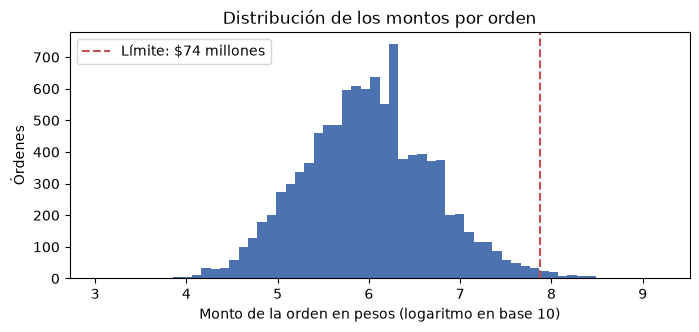

In [9]:
limit = ordenes.extreme_amount_limit(amount)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(np.log10(amount), bins=60, color="#4c72b0")
ax.axvline(np.log10(limit), color="#c44e52", linestyle="--", label=f"Límite: ${limit / 1e6:,.0f} millones")
ax.set_xlabel("Monto de la orden en pesos (logaritmo en base 10)")
ax.set_ylabel("Órdenes")
ax.set_title("Distribución de los montos por orden")
ax.legend()
plt.show()

In [10]:
# Comparación de criterios: cuántas órdenes marca cada uno y cuánto dinero concentran.
q1, q3 = amount.quantile(0.25), amount.quantile(0.75)
criteria = {
    "IQR sobre el monto en pesos": q3 + 1.5 * (q3 - q1),
    "IQR sobre el logaritmo (elegido)": limit,
    "Percentil 99": amount.quantile(0.99),
}
pd.DataFrame(
    {
        "límite ($)": criteria,
        "órdenes": {name: int((amount > value).sum()) for name, value in criteria.items()},
        "% de las órdenes": {name: (amount > value).mean() * 100 for name, value in criteria.items()},
        "% del monto": {name: amount[amount > value].sum() / amount.sum() * 100 for name, value in criteria.items()},
    }
)

,límite ($),órdenes,% de las órdenes,% del monto
IQR sobre el monto en pesos,"6,624,444.4",1197,11.6,74.9
IQR sobre el logaritmo (elegido),"74,012,533.3",84,0.8,33.5
Percentil 99,"64,332,919.2",103,1.0,36.2


El criterio habitual sobre el monto en pesos marcaría como extrema una de cada nueve órdenes: no separa lo excepcional de lo simplemente grande. Sobre el logaritmo quedan menos del 1 % de las órdenes, que concentran un tercio del dinero.

**Efecto sobre el indicador del proyecto:** participación de los diez mayores proveedores, con todas las órdenes y sin las extremas.

In [11]:
flagged = ordenes.flag_extreme_amounts(orders, limit)
effect = pd.DataFrame(
    {
        "órdenes extremas": flagged.groupby("periodo")["monto_extremo"].sum(),
        "% top 10, todas las órdenes": ordenes.top_supplier_share(flagged),
        "% top 10, sin las extremas": ordenes.top_supplier_share(flagged[~flagged["monto_extremo"]]),
    }
)
effect["diferencia (puntos)"] = effect["% top 10, sin las extremas"] - effect["% top 10, todas las órdenes"]
effect

,órdenes extremas,"% top 10, todas las órdenes","% top 10, sin las extremas",diferencia (puntos)
periodo,,,,
2024-09,33,22.2,16.1,-6.1
2025-09,51,26.0,15.4,-10.7


Con todas las órdenes, la participación de los diez mayores proveedores sube entre 2024 y 2025. Sin las órdenes extremas, baja y queda casi igual en los dos años. El aumento observado depende entonces de unas pocas compras muy grandes, no de un cambio general en la forma de comprar.

**Revisión de los extremos:** las órdenes más grandes, las más pequeñas y las que podrían estar repetidas con otro código.

In [12]:
columns = ["periodo", "modalidad", "UnidadCompra", "NombreProveedor", "MontoTotalOC_PesosChilenos", "lineas"]
flagged.nlargest(5, "MontoTotalOC_PesosChilenos")[columns]

,periodo,modalidad,UnidadCompra,NombreProveedor,MontoTotalOC_PesosChilenos,lineas
6666,2025-09,Otra,Hospital San Martín de Quillota,EDENRED CHILE SOCIEDAD ANONIMA,"1,601,438,750.0",1
4891,2025-09,Otra,SERVICIO DE SALUD VALPARAISO SAN ANTONIO,Rayen Salud SpA,"1,174,842,822.4",1
131,2024-09,Licitación,COMPRAS CONVENIO GORE VALPARAISO,Dikar S.A,"632,681,319.1",1
313,2024-09,Licitación,Hospital San Francisco de Llay Llay,GOPA SOLUCIONES SPA,"555,262,553.7",1
35,2024-09,Licitación,Servicio de Salud Viña del Mar - Quillota,SIENA SPA,"521,288,718.9",1


In [13]:
print(f"Órdenes bajo $10.000: {(amount < 10_000).sum()} · monto mínimo: ${amount.min():,.0f} · montos en cero o negativos: {(amount <= 0).sum()}")

# Mismo proveedor, unidad de compra, monto y fecha, con distinto código de orden.
key = ["periodo", "CodigoProveedor", "CodigoUnidadCompra", "MontoTotalOC_PesosChilenos", "FechaEnvio"]
repeated = flagged[flagged.duplicated(key, keep=False)]
print(f"Órdenes que coinciden con otra en proveedor, unidad, monto y fecha: {len(repeated)} en {repeated.groupby(key).ngroups} grupos")
print(f"Suman ${repeated['MontoTotalOC_PesosChilenos'].sum() / 1e6:,.0f} millones ({repeated['MontoTotalOC_PesosChilenos'].sum() / amount.sum():.1%} del total); extremas entre ellas: {int(repeated['monto_extremo'].sum())}")

Órdenes bajo $10.000: 18 · monto mínimo: $1,071 · montos en cero o negativos: 0
Órdenes que coinciden con otra en proveedor, unidad, monto y fecha: 280 en 119 grupos
Suman $946 millones (1.9% del total); extremas entre ellas: 0


**Decisión:** las órdenes extremas **se conservan y se marcan** con la variable `monto_extremo` (notebook 04).

- Son compras reales y vigentes: eliminarlas quitaría un tercio del gasto que se quiere estudiar.
- Como cambian la conclusión, los indicadores de concentración se informarán de las dos maneras: con todas las órdenes y sin las extremas.
- No hay montos en cero ni negativos. Las órdenes muy pequeñas son pocas y no pesan en el total: se conservan.
- Las órdenes que coinciden en proveedor, unidad, monto y fecha tienen códigos distintos y la fuente no permite saber si son un error o compras iguales emitidas el mismo día (algo habitual en compras periódicas). Se conservan y se declara como límite.

## 5. Hallazgos que orientan la limpieza

| Hallazgo | Consecuencia |
|---|---|
| Ausentes como celda vacía o texto `NA` | Unificarlos como NA reales (notebook 03) |
| Espacios al final de algunos textos | Recortarlos (notebook 03) |
| Montos con coma decimal, leídos como texto | Convertirlos a número (notebook 04) |
| Fechas leídas como texto | Convertirlas a fecha (notebook 04) |
| `EsTratoDirecto` cambia de significado en 2025 | Crear una variable `modalidad` comparable (notebook 04) |
| Varias líneas por orden, con el monto total repetido | Dejar una fila por orden antes de sumar (notebook 04) |
| Sin filas completamente repetidas | No se eliminan filas |
| Menos del 1 % de las órdenes concentra un tercio del monto y cambia el indicador de concentración | Marcarlas con `monto_extremo`, sin eliminarlas (notebook 04), e informar los indicadores con y sin ellas |